# 10f Stand-alone Automated Concept Refinement Cycle

This combines the inspectable stages in 10a–10d: prepare the pair-year corpus and split, create a mutable working catalog from the seed reference or resume the current working catalog, classify with the same Jev cache, build yearly signals, and run development forecasts. It repeats the proposal/classify/evaluate stages as a development-only refinement loop. This notebook can run from a clean checkout without first running 10a or 10b.

Edit the parameter block in the setup cell for pathogen limit, split, models, classification, forecasts, and refinement size. Defaults use the configured Jev model and `CHILD_GENERATION_MODEL` (default `gpt-6-astra`). The default search uses three rounds, up to three Pareto-front parents per round, and three children per parent.

Jev labels are cached per abstract and concept definition, so rerunning or adding children reuses unchanged labels. Proposals, round summaries, forecasts, catalog snapshots, and Pareto tables are saved under `outputs/concept_search/automated_refinement/`. Confirmation remains separate in notebook 10e after the catalog is frozen.


In [ ]:
from pathlib import Path
import sys
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config
from amr.pipelines.automated_concept_refinement import run_automated_concept_refinement
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

# Corpus and split parameters. All antibiotics are retained for selected pathogens.
NUM_PATHOGENS = 4
HELDOUT_FRACTION = 0.20
SPLIT_SEED = 42
RESET_CATALOG_TO_SEEDS = True
YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
ABSTRACT_CACHE_PATH = cfg_path(PIPELINE_CONFIG, "paths.abstract_cache", PROJECT_ROOT)
SI_PATH = PROJECT_ROOT / "outputs" / "parquets" / "yearly_si.parquet"
PATHOGEN_PRIORITY_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_priority", PROJECT_ROOT)
MIN_PATHOGENIC_INDEX = float(cfg(PIPELINE_CONFIG, "collection.min_pathogenic_index", 0))

# Jev classification and LLM proposal parameters.
JEV_MODEL = str(cfg(PIPELINE_CONFIG, "system1.model", "typesafe/jev-1.13"))
MAX_WORKERS = int(cfg(PIPELINE_CONFIG, "system1.max_workers", 128))
MAX_CLASSIFICATION_CALLS = None
CHILD_GENERATION_MODEL = str(cfg(PIPELINE_CONFIG, "llm.child_generation_model", "gpt-6-astra"))
LLM_TEMPERATURE = 0
LLM_MAX_TOKENS = 4000
MAX_EXAMPLES_PER_PARENT = 30
PROPOSAL_EXAMPLE_SEED = 42
POSITIVE_EXAMPLE_THRESHOLD = 0.5

# Expanding-window forecast parameters.
FIT_START_YEAR = int(cfg(PIPELINE_CONFIG, "si.fit_start_year", 2000))
FORECAST_ORIGIN_END_YEAR = int(cfg(PIPELINE_CONFIG, "si.fit_end_year", 2023))
LAG_LENGTH = 3
FORECAST_HORIZONS = (1, 2, 3)
MIN_PRIOR_OBSERVATIONS = 10
FORECAST_PROGRESS_EVERY = 10
FRONTIER_DISPLAY_ROWS = 30

# Automated search parameters.
N_ITER = 3
K_PARENTS = 3
NUM_CHILDREN = 3
RUN_AUTOMATED_CYCLE = True

PARAMETERS = {name: value for name, value in locals().copy().items() if name in {
    'YEARLY_SCREENED_PATH', 'ABSTRACT_CACHE_PATH', 'SI_PATH', 'PATHOGEN_PRIORITY_PATH', 'MIN_PATHOGENIC_INDEX', 'NUM_PATHOGENS', 'HELDOUT_FRACTION', 'SPLIT_SEED', 'RESET_CATALOG_TO_SEEDS', 'JEV_MODEL', 'MAX_WORKERS', 'MAX_CLASSIFICATION_CALLS', 'CHILD_GENERATION_MODEL', 'LLM_TEMPERATURE', 'LLM_MAX_TOKENS', 'MAX_EXAMPLES_PER_PARENT', 'PROPOSAL_EXAMPLE_SEED', 'POSITIVE_EXAMPLE_THRESHOLD', 'FIT_START_YEAR', 'FORECAST_ORIGIN_END_YEAR', 'LAG_LENGTH', 'FORECAST_HORIZONS', 'MIN_PRIOR_OBSERVATIONS', 'FORECAST_PROGRESS_EVERY', 'FRONTIER_DISPLAY_ROWS', 'N_ITER', 'K_PARENTS', 'NUM_CHILDREN', 'RUN_AUTOMATED_CYCLE'}}


## Prepare corpus, split, and starting catalog

This stage duplicates notebook 10a’s preparation so 10f is runnable on its own: it joins screened PMID membership, cached abstracts, and observed SI; applies the pathogen limit before pair splitting; writes the corpus artifacts; and prints coverage/request-volume preflight before any Jev or LLM calls. The split is deterministic by pathogen–antibiotic pair.

The confirmation partition is kept out of proposal examples and model selection. Shared PMIDs are excluded from proposal examples even when the article appears in both pair partitions. `RESET_CATALOG_TO_SEEDS=True` copies the nine seed concepts into a fresh working catalog for this run; the hash-named seed snapshot remains as the immutable reference. Each iteration extends the working catalog and writes a versioned snapshot. Set it to `False` to load the current working catalog and add another `N_ITER` rounds on a later run. Classification scores remain cached by PMID and concept definition.


The setup cell exposes input paths, pathogen cap, split seed/fraction, catalog reset behavior, Jev and child-generation models, worker/call limits, prompt example threshold and sample size, fit years, lag length, forecast horizons, minimum prior observations, progress interval, and refinement counts. Change those values there; the notebook records the corpus/catalog and forecast settings in its run directory name.


If MAX_CLASSIFICATION_CALLS is capped, 10f stops before forecasting when labels remain missing; rerun to resume without treating missing labels as zero prevalence.


## Run the automated development loop

The first evaluation scores the starting catalog. In each round, the notebook computes a Pareto frontier from equal-weight gains across `FORECAST_HORIZONS`. A concept is on the frontier when no other evaluated concept has both higher generality and higher specialist strength. From the unexpanded frontier it selects up to `K_PARENTS`, ordered by average gain and then specialist strength.

For each selected parent, the LLM receives up to `MAX_EXAMPLES_PER_PARENT` positive, development-exclusive abstract examples and the parent definition. It is asked for `NUM_CHILDREN` child concepts. The notebook saves each proposal, adds valid nonduplicate children to the catalog, asks Jev only for missing child labels, and evaluates those children on development pairs. New children enter the Pareto pool for the next round. Each round also estimates conditional contribution by comparing the selected population with and without each selected concept. For every expanded parent, nested estimates compare the full selected population against the same Pareto survivor population with that parent replaced by its children; single-child replacement estimates are saved too. These comparisons hold the remaining population fixed and never add children on top of their parent. If fewer than `K_PARENTS` unexpanded frontier concepts remain, the cycle stops early.

The procedure is automated, so inspect its proposals and selection summaries before interpreting them. The 90th-percentile objective protects specialist concepts during selection; the final parent ranking within that frontier uses average improvement, as requested.

For every accepted child, the iteration output prints its name, definition, parent, rationale, inclusion/exclusion criteria, evidence, competing concept, distinction, expected timing, hypothesis, and rejection conditions. The full response is also retained in that parent’s saved proposal JSON.


Progress messages are printed for the initial evaluation, each iteration, each selected parent, proposal/cache loading, classification, and evaluation. The selected Pareto parents are listed with generality and 90th-percentile specialist strength; accepted children print their full refinement details. Jev classification and rolling forecasts also report progress and ETA.

The same parent names, IDs, and selection scores are recorded in `iteration_history.json` for later review.


At the end of each iteration, 10f displays and saves a plot of generality versus specialist strength. It distinguishes previously evaluated concepts, parents selected that round, newly evaluated children, and parent-to-child-set replacement results; dashed zero lines mark no improvement.


{'selected_pathogens': 2, 'pathogen_limit': 2, 'all_antibiotics_retained': True, 'pair_year_pmid_associations': 15900, 'unique_pmids': 7394, 'unique_nonblank_abstracts_to_classify': 7394, 'abstract_coverage': 1.0, 'full_corpus_jev_request_upper_bound_if_uncached': 7394, 'estimated_pending_jev_requests_after_cache': 0, 'abstracts_with_all_current_concept_labels_cached': 7394, 'development_pairs': 34, 'confirmation_pairs': 8, 'starting_catalog_version': '54d79903b1dbf073', 'starting_catalog_reference': '/Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/catalog_versions/concept_catalog_54d79903b1dbf073.json', 'seed_reference_version': '54d79903b1dbf073', 'starting_concepts': 9, 'run_directory': '/Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_378c511b3c5f_catalog_54d79903b1dbf073_n3_k3_c3_fit2000-2023_l3_h1-2-3_b81f0c14'}
[10:45:16] Starting catalog evaluation: 9 concepts; catalog 54d79903b1dbf073.
[10:45:16] Initial catalo

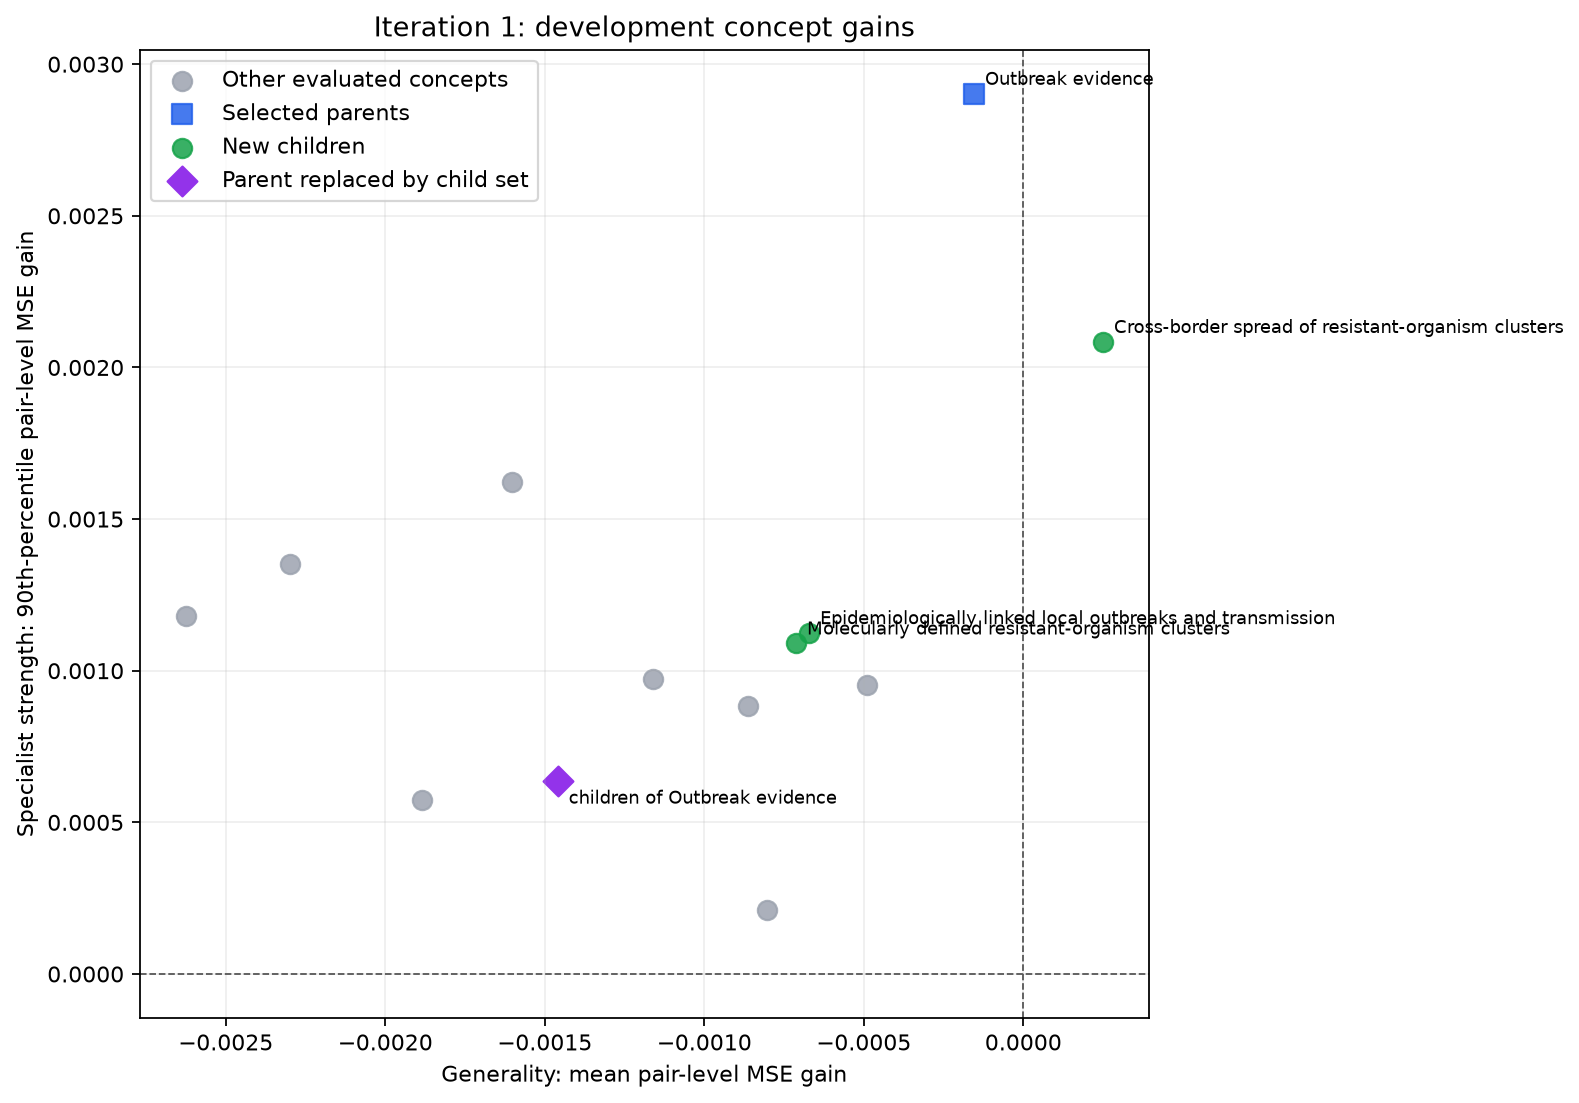

[10:49:04] Iteration 1: progress plot saved to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_378c511b3c5f_catalog_54d79903b1dbf073_n3_k3_c3_fit2000-2023_l3_h1-2-3_b81f0c14/iteration_01_progress.png.
[10:49:04] Iteration 1 result: outbreak_evidence (expanded) → outbreak_evidence_molecularly_defined_resistant_organism_clusters, outbreak_evidence_epidemiologically_linked_local_outbreaks_and_transmission, outbreak_evidence_cross_border_spread_of_resistant_organism_clusters
[10:49:04] Iteration 1/3: round status = evaluated; history saved.
[10:49:04] Iteration 2/3: combining current concept results and selecting parents.
[10:49:04] Iteration 2/3: 2 concepts on the Pareto frontier; 1 are eligible for expansion.
[10:49:04] Iteration 2/3: selected 1 parent(s) for expansion:
[10:49:04]   Parent 1/1: Cross-border spread of resistant-organism clusters [outbreak_evidence_cross_border_spread_of_resistant_organism_clusters] | average gain=0.000249257

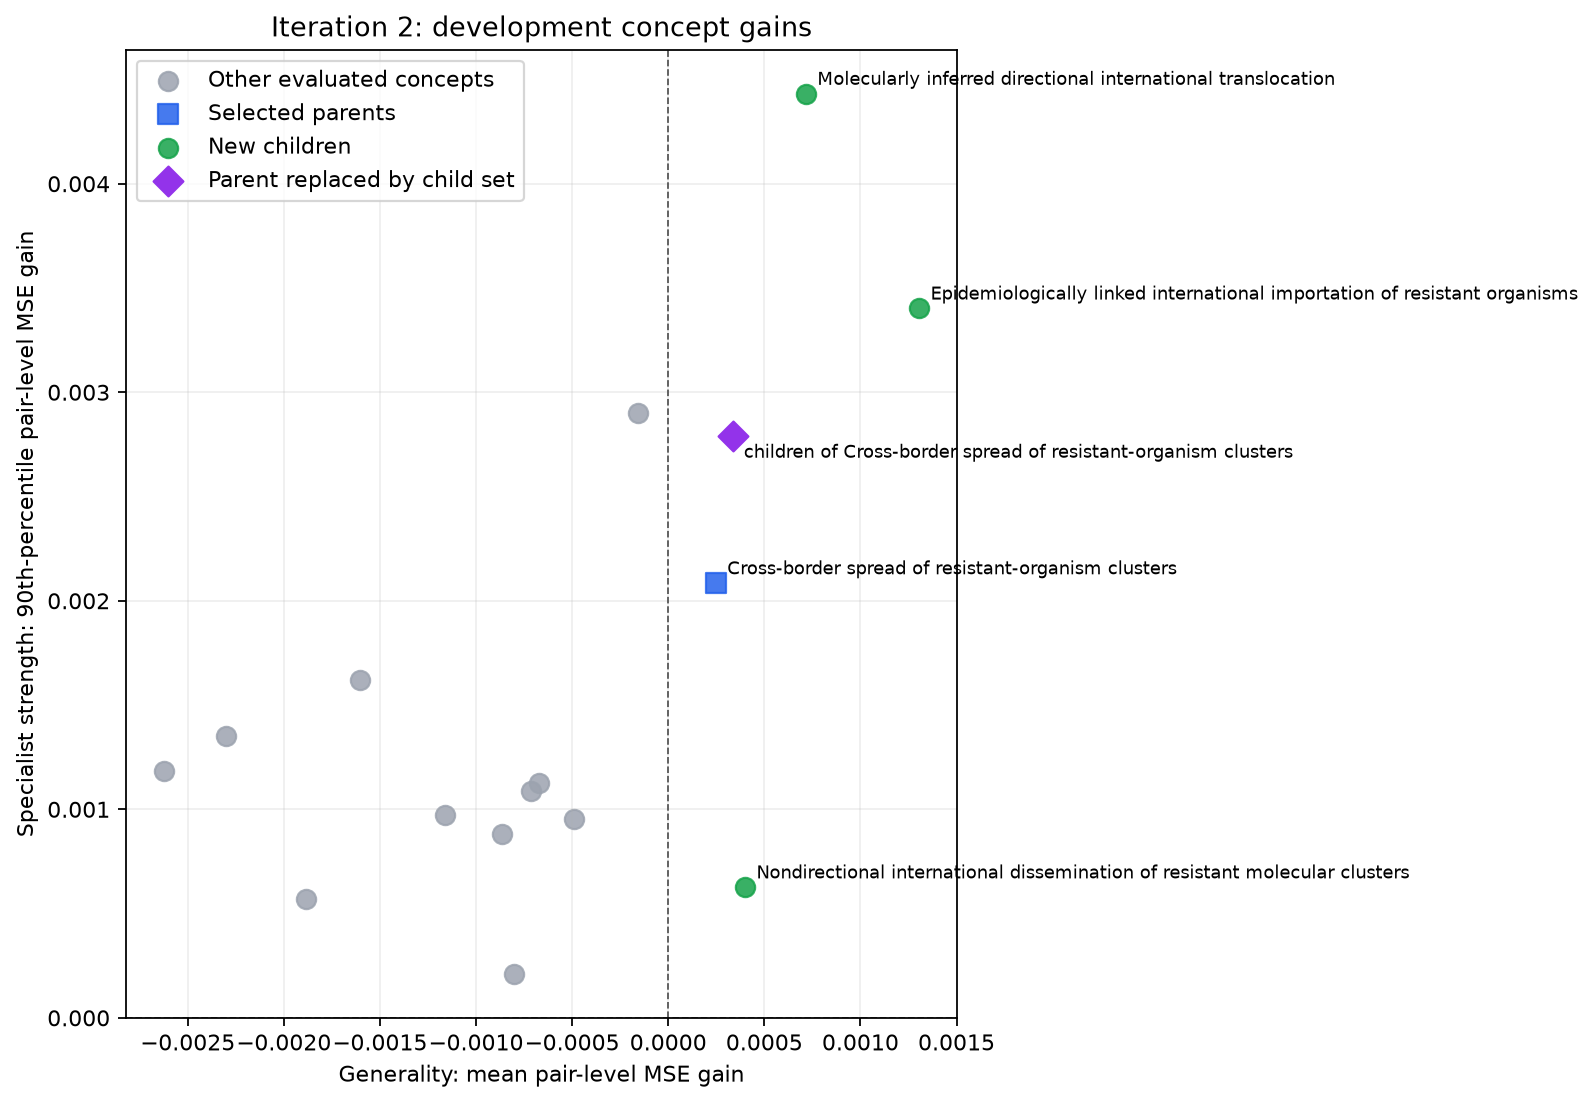

[10:52:14] Iteration 2: progress plot saved to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_378c511b3c5f_catalog_54d79903b1dbf073_n3_k3_c3_fit2000-2023_l3_h1-2-3_b81f0c14/iteration_02_progress.png.
[10:52:14] Iteration 2 result: outbreak_evidence_cross_border_spread_of_resistant_organism_clusters (expanded) → outbreak_evidence_cross_border_spread_of_resistant_organism_clusters_epidemiologically_linked_international_importation_of_resistant_organisms, outbreak_evidence_cross_border_spread_of_resistant_organism_clusters_molecularly_inferred_directional_international_translocation, outbreak_evidence_cross_border_spread_of_resistant_organism_clusters_nondirectional_international_dissemination_of_resistant_molecular_clusters
[10:52:14] Iteration 2/3: round status = evaluated; history saved.
[10:52:14] Iteration 3/3: combining current concept results and selecting parents.
[10:52:14] Iteration 3/3: 2 concepts on the Pareto frontier; 2 are el

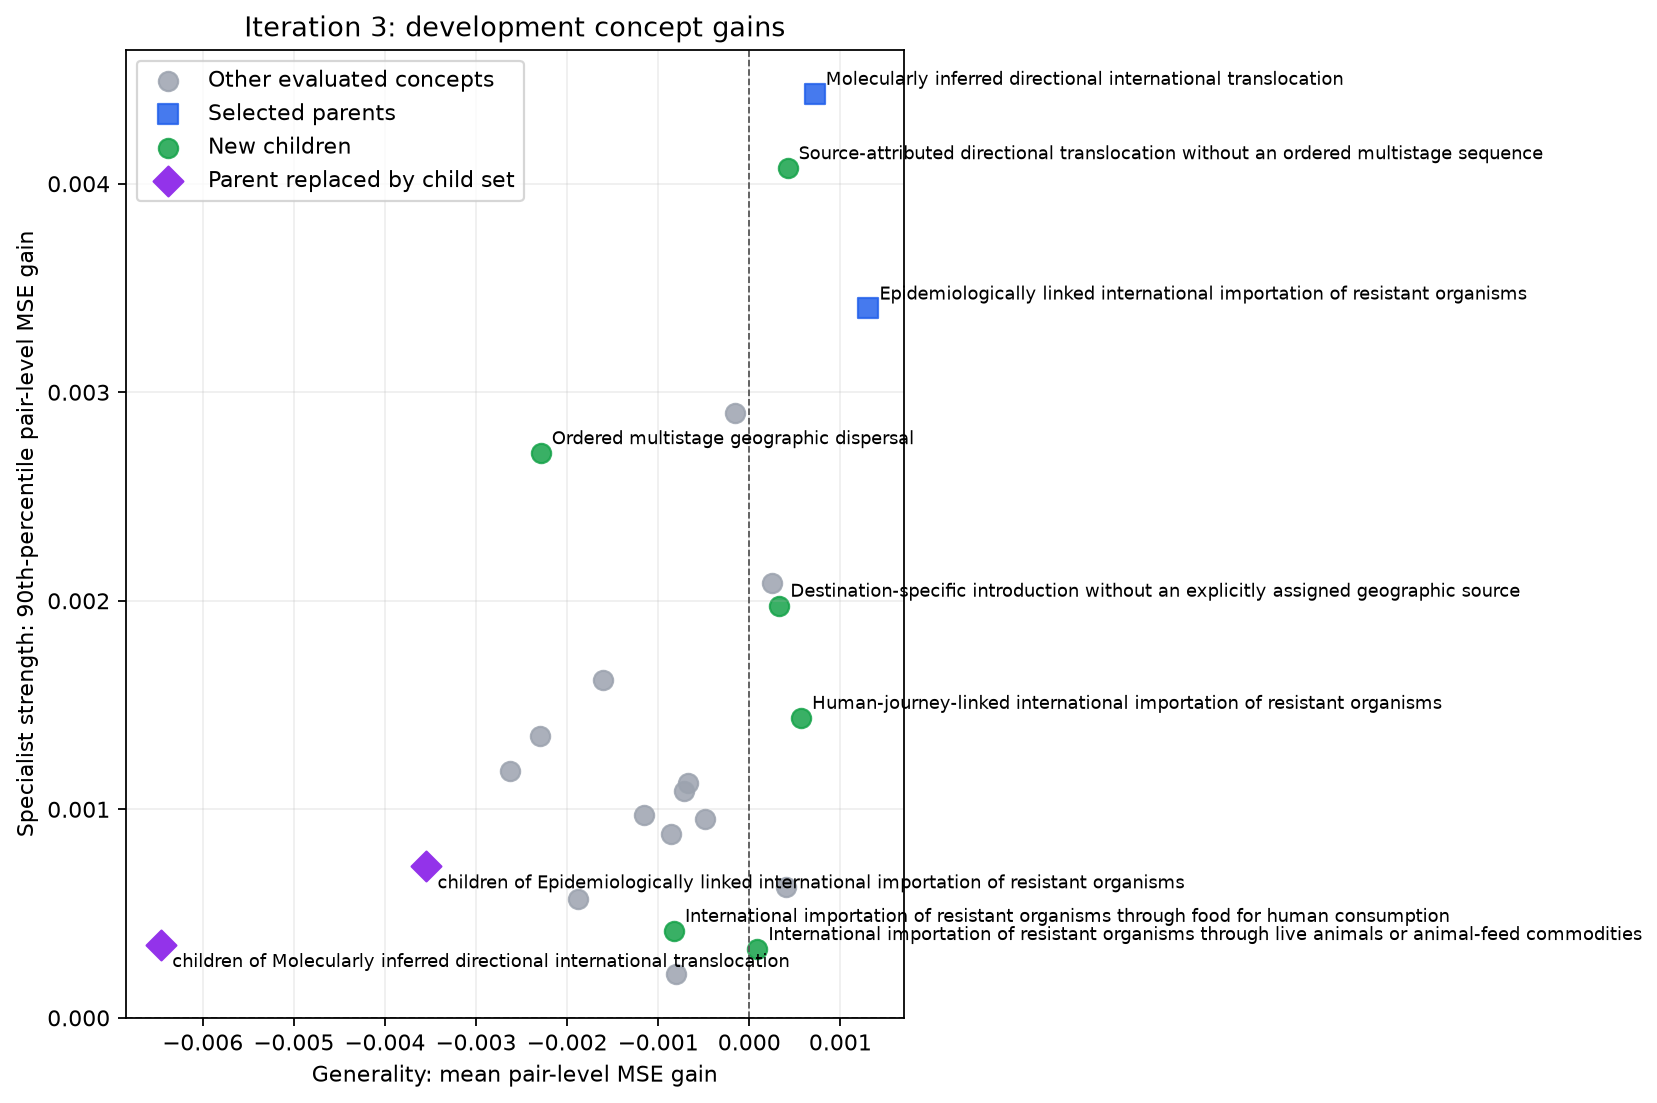

[10:57:43] Iteration 3: progress plot saved to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_378c511b3c5f_catalog_54d79903b1dbf073_n3_k3_c3_fit2000-2023_l3_h1-2-3_b81f0c14/iteration_03_progress.png.
[10:57:43] Iteration 3 result: outbreak_evidence_cross_border_spread_of_resistant_organism_clusters_epidemiologically_linked_international_importation_of_resistant_organisms (expanded) → outbreak_evidence_cross_border_spread_of_resistant_organism_clusters_epidemiologically_linked_international_importation_of_resistant_organisms_human_journey_linked_international_importation_of_resistant_organisms, outbreak_evidence_cross_border_spread_of_resistant_organism_clusters_epidemiologically_linked_international_importation_of_resistant_organisms_international_importation_of_resistant_organisms_through_food_for_human_consumption, outbreak_evidence_cross_border_spread_of_resistant_organism_clusters_epidemiologically_linked_international_importation_of

/Users/f.costa/Code/Antimicrobial-Resistance/amr/pipelines/automated_concept_refinement.py:121: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


Final concept phylogeny: roots at left; × marks terminal dead ends; thick blue paths end at final Pareto survivors.
Final Pareto survivors: Epidemiologically linked international importation of resistant organisms, Molecularly inferred directional international translocation
[10:57:43] Final Pareto frontier (with expansion status):
[10:57:43] Automated development cycle complete. Catalog 30f3b61f27cb8c5f; outputs: /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_378c511b3c5f_catalog_54d79903b1dbf073_n3_k3_c3_fit2000-2023_l3_h1-2-3_b81f0c14
{'run_directory': '/Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_378c511b3c5f_catalog_54d79903b1dbf073_n3_k3_c3_fit2000-2023_l3_h1-2-3_b81f0c14', 'catalog_version': '30f3b61f27cb8c5f', 'iterations': 3}


,model,reference_model,horizon,generality,specialist_strength,pairs,concept_id,on_pareto_front,eligible_for_expansion
0,concept:outbreak_evidence_cross_border_spread_...,baseline,0,0.001307,0.003402,27,outbreak_evidence_cross_border_spread_of_resis...,True,False
1,concept:outbreak_evidence_cross_border_spread_...,baseline,0,0.000718,0.004431,27,outbreak_evidence_cross_border_spread_of_resis...,True,False
2,concept:outbreak_evidence_cross_border_spread_...,baseline,0,0.000568,0.001439,27,outbreak_evidence_cross_border_spread_of_resis...,False,True
3,concept:outbreak_evidence_cross_border_spread_...,baseline,0,0.000420,0.004075,27,outbreak_evidence_cross_border_spread_of_resis...,False,True
4,concept:outbreak_evidence_cross_border_spread_...,baseline,0,0.000401,0.000626,27,outbreak_evidence_cross_border_spread_of_resis...,False,True
5,concept:outbreak_evidence_cross_border_spread_...,baseline,0,0.000329,0.001977,27,outbreak_evidence_cross_border_spread_of_resis...,False,True
6,concept:outbreak_evidence_cross_border_spread_...,baseline,0,0.000249,0.002084,27,outbreak_evidence_cross_border_spread_of_resis...,False,False
7,concept:outbreak_evidence_cross_border_spread_...,baseline,0,0.000088,0.000330,27,outbreak_evidence_cross_border_spread_of_resis...,False,True
8,concept:outbreak_evidence,baseline,0,-0.000155,0.002902,27,outbreak_evidence,False,False
9,concept:hospital_transmission,baseline,0,-0.000489,0.000952,27,hospital_transmission,False,True


Saved final concept phylogeny: /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_378c511b3c5f_catalog_54d79903b1dbf073_n3_k3_c3_fit2000-2023_l3_h1-2-3_b81f0c14/final_concept_phylogeny.png


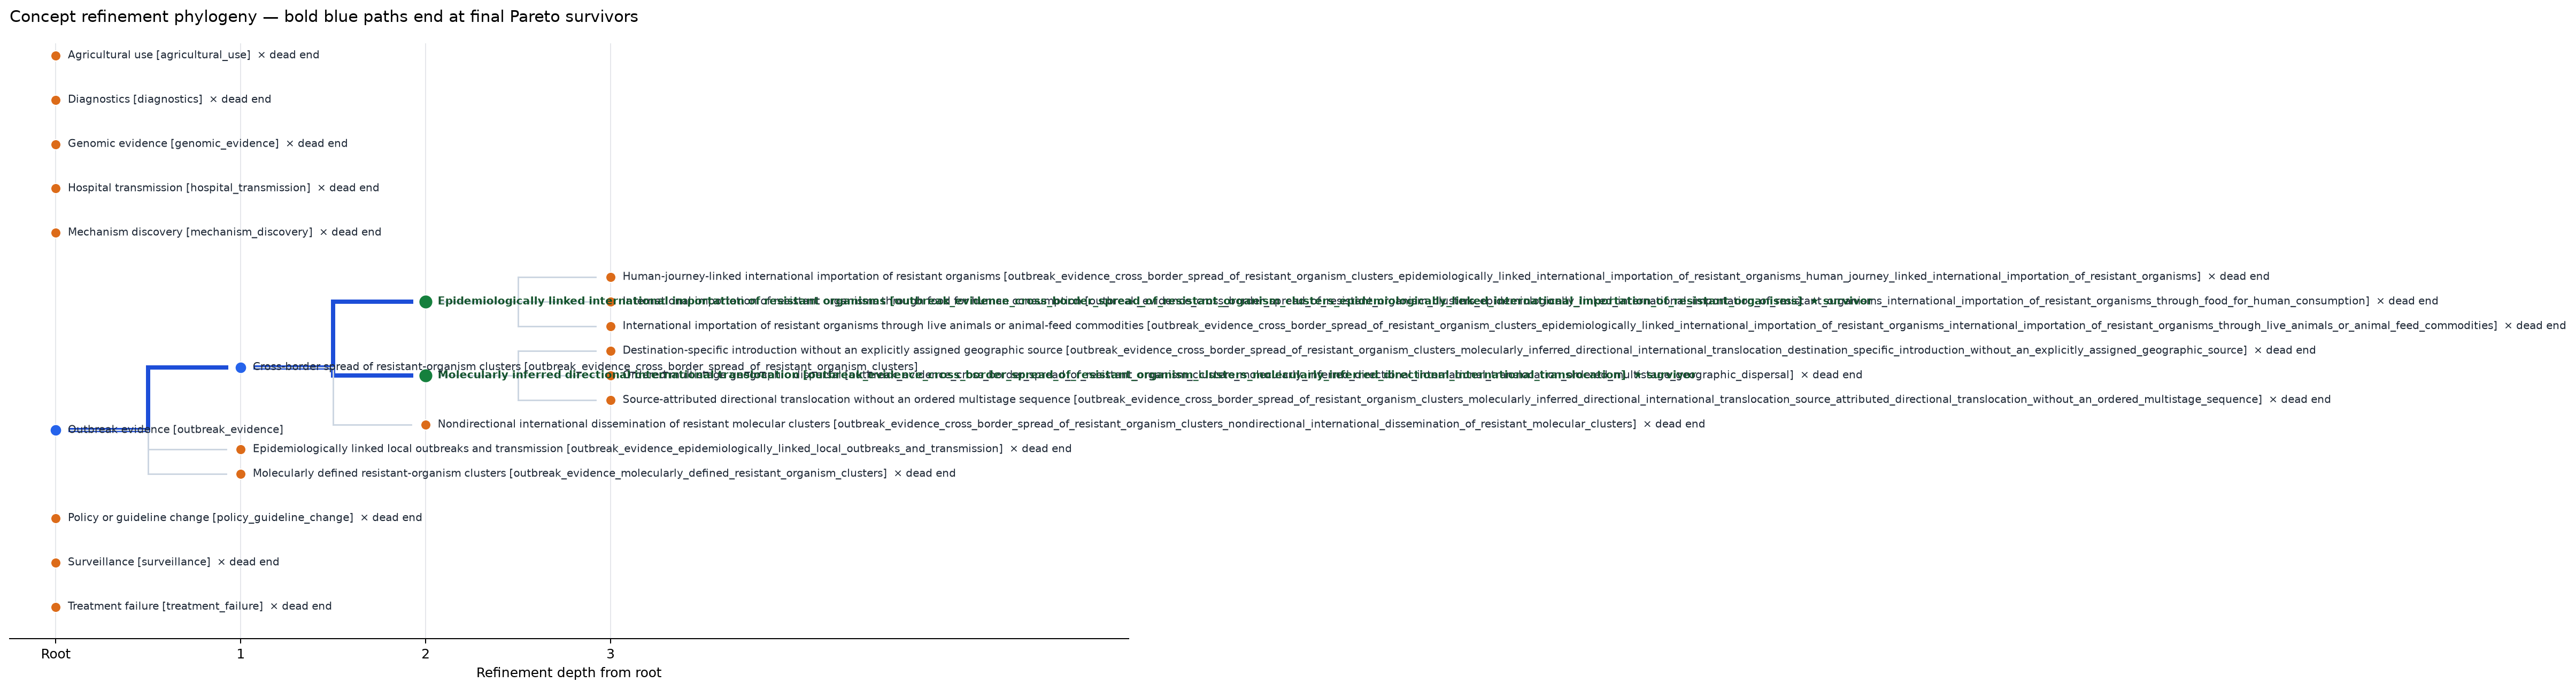

In [2]:
RESULT = run_automated_concept_refinement(PROJECT_ROOT, PARAMETERS, plot_callback=lambda path: display(Image(filename=str(path))))
if RESULT.get("status") == "disabled":
    print(RESULT["status"])
else:
    print({"run_directory": str(RESULT["run_directory"]), "catalog_version": RESULT["catalog_version"], "iterations": len(RESULT["round_log"])})
    display(RESULT["final_frontier"].head(FRONTIER_DISPLAY_ROWS))
    print("Saved final concept phylogeny:", RESULT["phylogeny_path"])
    display(Image(filename=str(RESULT["phylogeny_path"])))


## After the automated rounds

Inspect `iteration_history.json`, per-round proposals and forecasts, and the final Pareto table. Confirm the children’s definitions and hierarchy, then use notebook 10e to evaluate the frozen catalog on confirmation pairs. Update its expected catalog hash to the final catalog version before running it. Do not use confirmation results to revise the vocabulary.